In [1]:
import matplotlib.pyplot as plt
import numpy as np
import skimage
import utils


In [99]:
def convolve_im_spatial(im: np.array,
                kernel: np.array,
                verbose=True):
    """ Convolves the image (im) with the spatial kernel (kernel),
        and returns the resulting image.

        "verbose" can be used for turning on/off visualization
        convolution
        
        Note: kernel can be of different shape than im.

    Args:
        im: np.array of shape [H, W]
        kernel: np.array of shape [K, K] 
        verbose: bool
    Returns:
        im: np.array of shape [H, W]
    """
    ### START YOUR CODE HERE ### (You can change anything inside this block)
    orig_im = im.copy()
    orig_shape = im.shape
    orig_kernel = kernel.copy()
    conv_result = np.zeros_like(im, dtype=float)
    kernel = np.flipud(np.fliplr(kernel))     # flipping the kernel to apply a convolution
    kernel_half_size = len(kernel)//2
    kernel = np.pad(kernel, orig_shape)
    new_kernel_half_size = len(kernel)//2

    for i in range(len(im)):
        for j in range(len(im[i])):
            # Convolution so going from bottom to top and from right to left in the kernel
            for k in range(-kernel_half_size, kernel_half_size+1):
                for l in range(-kernel_half_size, kernel_half_size+1):
                    try:
                        conv_result[i, j] += kernel[new_kernel_half_size+k, new_kernel_half_size+l]*im[i+k, j+l]
                    except IndexError:
                        # Index out of bound: returning zero (to imitate a zero padding)
                        pass

    

    if verbose:
        # Use plt.subplot to place two or more images beside eachother
        plt.figure(figsize=(20, 4))
        # plt.subplot(num_rows, num_cols, position (1-indexed))
        plt.subplot(1, 5, 1)
        plt.imshow((orig_im.astype('float')), cmap="gray")
        plt.title("Original Image")
        
        plt.subplot(1, 5, 2) 
        # Visualize FFT
        plt.imshow(np.log(np.abs(np.fft.fftshift(np.fft.fft2(orig_im)))), cmap="gray")
        plt.title("FFT Image")
        
        plt.subplot(1, 5, 3)
        # Visualize FFT kernel
        plt.imshow(np.log(np.abs(np.fft.fftshift(np.fft.fft2(kernel)))), cmap="gray")
        plt.title("FFT Kernel")
        
        plt.subplot(1, 5, 4)
        # Visualize filtered FFT image
        plt.imshow(np.log(np.abs(np.fft.fftshift(np.fft.fft2(conv_result)))), cmap="gray")
        plt.title("Filtered FFT Image")
        
        plt.subplot(1, 5, 5) 
        # Visualize filtered spatial image
        plt.imshow(conv_result, cmap="gray")
        plt.title("Filtered Spatial Image")

    ### END YOUR CODE HERE ###
    return conv_result

/tmp/ipykernel_41784/3254000189.py:57: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(np.abs(np.fft.fftshift(np.fft.fft2(kernel)))), cmap="gray")


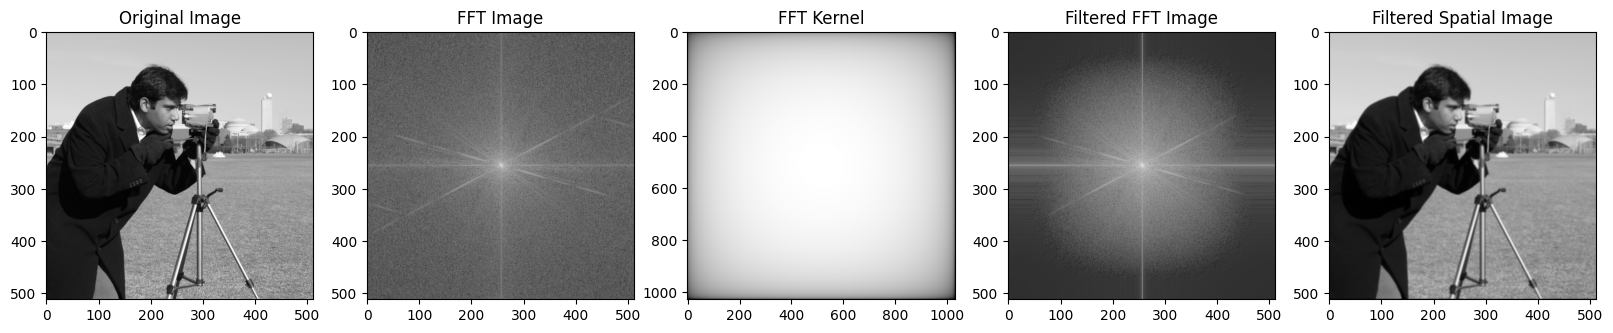

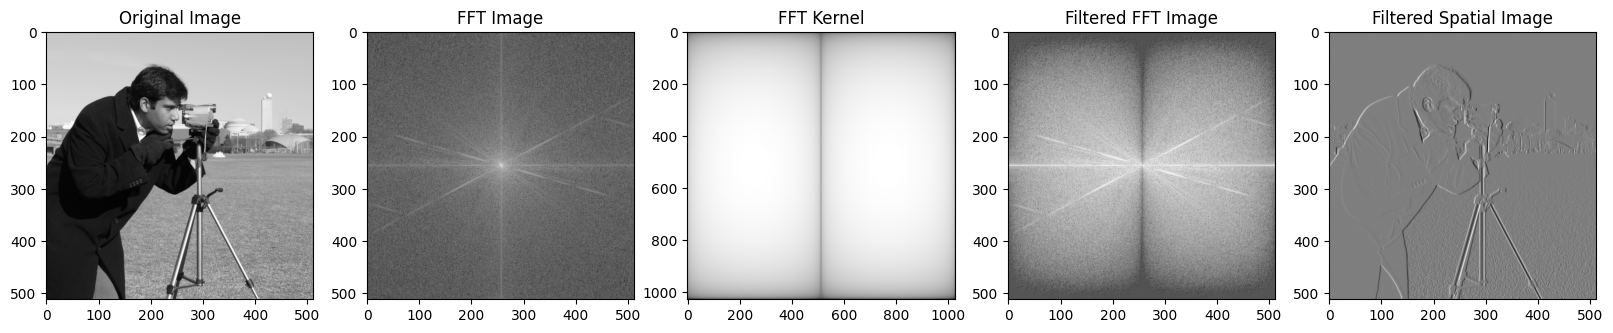

Saving image to: image_processed/camera_gaussian.png
Saving image to: image_processed/camera_sobelx.png


/home/clem/Bureau/Visual_Computing_Fundamentals/Part2_Image_Processing/Assignments/TDT4195-StarterCode-2025/Assignment 2/utils.py:27: UserWarning: Image min/max is outside the range [0.0, 1.0]. Squashing the image to this range. (Can be safely ignored)
  warnings.warn("Image min/max is outside the range [0.0, 1.0]. Squashing the image to this range. (Can be safely ignored)")


In [100]:
if __name__ == "__main__":
    verbose = True  # change if you want

    # Changing this code should not be needed
    im = skimage.data.camera()
    im = utils.uint8_to_float(im)

    # DO NOT CHANGE
    gaussian_kernel = np.array([
        [1, 4, 6, 4, 1],
        [4, 16, 24, 16, 4],
        [6, 24, 36, 24, 6],
        [4, 16, 24, 16, 4],
        [1, 4, 6, 4, 1],
    ]) / 256
    image_gaussian = convolve_im_spatial(im, gaussian_kernel, verbose)

    # DO NOT CHANGE
    sobel_horizontal = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ])
    image_sobelx = convolve_im_spatial(im, sobel_horizontal, verbose)

    if verbose:
        plt.show()

    utils.save_im("camera_gaussian.png", image_gaussian)
    utils.save_im("camera_sobelx.png", image_sobelx)

In [101]:
from scipy.signal import convolve2d
from skimage.metrics import structural_similarity as ssim

gt = convolve2d(im, sobel_horizontal, mode="same", boundary="fill", fillvalue=0)
similarity = ssim(image_sobelx, gt, data_range=im.max() - im.min())
print(similarity) # tolerance = 0.95

0.997296799592891
